# 04 · Models

Three steps, in the order the team agreed: screen every feature set with one untuned model, tune
only the winner with Optuna, then calibrate. Nothing is selected on a test set at any point.
Validation decides; the scaffold test set and the plant holdout are read once at the end.

**Two numbers are reported throughout and neither is dropped.** The scaffold test set is the
evaluation the repo settled on. The plant holdout is the set the deliverable is actually drawn
from, and 03 showed it sits much further from training (median nearest Tanimoto 0.39 to 0.47
against 0.67 to 0.70 for the scaffold test set). They answer different questions and the gap
between them is a result, not a discrepancy.

**The headline metric is precision at the head of the ranking**, not AUROC. The cost in this
project is a wasted synthesis, so what matters is the share of genuine actives among the handful of
compounds that would actually be made.

**Output.** `data/processed/04_models_<organism>.pkl` and scored predictions for 05. Figures `04_*`.

Code: `pipeline/models.py`, `pipeline/featureset.py`.

## 0. Settings

In [1]:
import hashlib
import json
import os
import pickle
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from pipeline import curation, data, featureset, ledger, models, viz

viz.use_style()
pd.set_option("display.width", 220)

CONFIG = {
    "pathogens": curation.PATHOGENS,
    "feature_sets": ["morgan", "descriptors", "hybrid"],
    "screen_models": ["random_forest", "gradient_boosting"],
    "screen_seeds": [0, 1, 2],
    "optuna_trials": int(os.environ.get("ETHNOHACK_TRIALS", 30)),
    "retune": os.environ.get("ETHNOHACK_RETUNE", "0") == "1",
    "calibration": "isotonic on the validation partition, model held fixed",
    "selection_rule": "validation AUROC, averaged over seeds; test sets never consulted",
    "seed": 0,
}
pd.Series(CONFIG, name="value").to_frame()

,value
pathogens,"[Staphylococcus aureus, Escherichia coli, Myco..."
feature_sets,"[morgan, descriptors, hybrid]"
screen_models,"[random_forest, gradient_boosting]"
screen_seeds,"[0, 1, 2]"
optuna_trials,30
retune,False
calibration,"isotonic on the validation partition, model he..."
selection_rule,"validation AUROC, averaged over seeds; test se..."
seed,0


## 1. Load what 03 built

Fingerprints are stored packed in the npz. They are only ever unpacked through
`featureset.matrices`, which checks the width: a packed array fed straight to a model trains on
byte values and still returns a plausible-looking number.

In [2]:
bundles, parts = {}, {}
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    bundle = featureset.load(f"03_features_{slug}")
    frame = pd.read_parquet(data.PROCESSED / f"03_splits_{slug}.parquet")
    assert list(frame.skeleton) == list(bundle["skeleton"]), "split file and features disagree"
    bundles[organism] = bundle
    parts[organism] = {
        name: np.where(frame.partition.eq(name).to_numpy())[0]
        for name in ("train", "validation", "test", "plant")
    }
    sizes = {k: len(v) for k, v in parts[organism].items()}
    print(f"{organism}: {sizes}")

Staphylococcus aureus: {'train': 39970, 'validation': 8573, 'test': 8567, 'plant': 1432}
Escherichia coli: {'train': 29733, 'validation': 6372, 'test': 6404, 'plant': 867}
Mycobacterium tuberculosis: {'train': 15713, 'validation': 3368, 'test': 3371, 'plant': 688}


## 2. The screen

Two model families against three feature sets, three seeds each, scored on validation. Three seeds
is enough to say whether a gap is real: 03's single untuned fit put morgan and hybrid within 0.003
of each other, which is not a difference anyone should act on.

In [3]:
screen_rows = []
for organism in CONFIG["pathogens"]:
    bundle = bundles[organism]
    part = parts[organism]
    y = bundle["label"]
    matrices = featureset.matrices(bundle)
    weight = models.positive_weight(y[part["train"]])
    for feature_name in CONFIG["feature_sets"]:
        X = matrices[feature_name]
        for model_name in CONFIG["screen_models"]:
            for seed in CONFIG["screen_seeds"]:
                start = time.time()
                if model_name == "random_forest":
                    model = models.random_forest(seed=seed, n_estimators=200)
                else:
                    model = models.gradient_boosting(seed=seed, scale_pos_weight=weight)
                model.fit(X[part["train"]], y[part["train"]])
                scores = model.predict_proba(X[part["validation"]])[:, 1]
                screen_rows.append({
                    "pathogen": organism,
                    "feature set": feature_name,
                    "model": model_name,
                    "seed": seed,
                    "validation AUROC": models.roc_auc_score(y[part["validation"]], scores),
                    "seconds": round(time.time() - start, 1),
                })
            last = screen_rows[-1]
            print(f"  {organism[:14]:14s} {feature_name:11s} {model_name:17s} "
                  f"{last['validation AUROC']:.3f}  ({last['seconds']:.0f}s)", flush=True)
    del matrices
screen = pd.DataFrame(screen_rows)
summary = screen.groupby(["pathogen", "feature set", "model"])["validation AUROC"].agg(
    mean="mean", sd="std"
)
summary.style.format({"mean": "{:.3f}", "sd": "{:.3f}"})

  Staphylococcus morgan      random_forest     0.870  (8s)


  Staphylococcus morgan      gradient_boosting 0.852  (8s)


  Staphylococcus descriptors random_forest     0.809  (2s)


  Staphylococcus descriptors gradient_boosting 0.794  (1s)


  Staphylococcus hybrid      random_forest     0.871  (5s)


  Staphylococcus hybrid      gradient_boosting 0.862  (7s)


... (8 outputs left out)

  Mycobacterium  descriptors random_forest     0.700  (1s)


  Mycobacterium  descriptors gradient_boosting 0.697  (1s)


  Mycobacterium  hybrid      random_forest     0.832  (2s)


  Mycobacterium  hybrid      gradient_boosting 0.815  (3s)


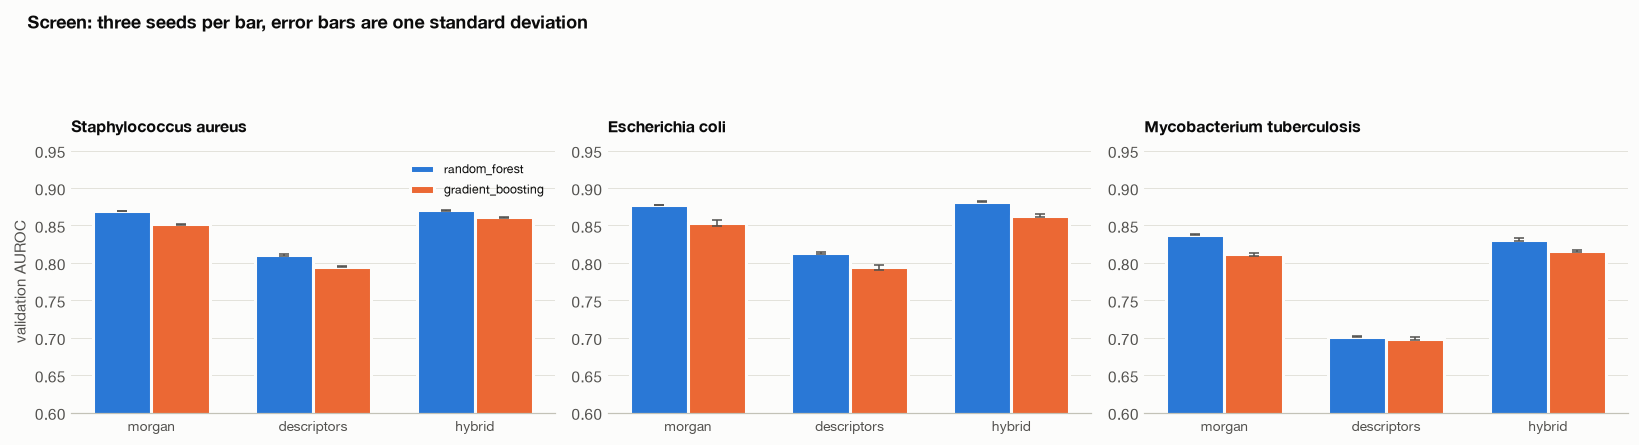

Staphylococcus aureus: hybrid + random_forest (0.870 +/- 0.001)
Escherichia coli: hybrid + random_forest (0.882 +/- 0.001)
Mycobacterium tuberculosis: morgan + random_forest (0.838 +/- 0.001)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    block = summary.loc[organism]
    x = np.arange(len(CONFIG["feature_sets"]))
    width = 0.36
    for i, model_name in enumerate(CONFIG["screen_models"]):
        means = [block.loc[(f, model_name), "mean"] for f in CONFIG["feature_sets"]]
        sds = [block.loc[(f, model_name), "sd"] for f in CONFIG["feature_sets"]]
        ax.bar(x + (i - 0.5) * width, means, width=width, yerr=sds, capsize=3,
               color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=2,
               error_kw=dict(ecolor=viz.INK_SECONDARY, lw=1), label=model_name)
    ax.set_xticks(x, CONFIG["feature_sets"], fontsize=9)
    ax.set_ylim(0.6, 0.95)
    ax.set_title(organism, fontsize=10.5)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("validation AUROC")
axes[0].legend(fontsize=8)
fig.suptitle("Screen: three seeds per bar, error bars are one standard deviation",
             x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_screen")
plt.show()

winners = {}
for organism in CONFIG["pathogens"]:
    block = summary.loc[organism].reset_index()
    best = block.sort_values("mean", ascending=False).iloc[0]
    winners[organism] = (best["feature set"], best["model"])
    print(f"{organism}: {best['feature set']} + {best['model']} "
          f"({best['mean']:.3f} +/- {best['sd']:.3f})")

## 3. Tuning the winner with Optuna

Optuna only, on the winning combination for each pathogen, maximising validation AUROC. The search
adapts to earlier trials rather than walking a grid, which is why the team chose it. The test sets
are not touched.

In [5]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def data_fingerprint(organism):
    bundle, part = bundles[organism], parts[organism]
    assignment = np.zeros(len(bundle["label"]), dtype=np.int8)
    for value, name in enumerate(("train", "validation", "test", "plant")):
        assignment[part[name]] = value
    digest = hashlib.sha256()
    digest.update(np.ascontiguousarray(bundle["label"]))
    digest.update(np.ascontiguousarray(assignment))
    return digest.hexdigest()[:12]


tuning_source = {}

studies, tuned = {}, {}
for organism in CONFIG["pathogens"]:
    feature_name, model_name = winners[organism]
    bundle = bundles[organism]
    part = parts[organism]
    y = bundle["label"]
    X = featureset.matrices(bundle)[feature_name]
    weight = models.positive_weight(y[part["train"]])
    Xtr, ytr = X[part["train"]], y[part["train"]]
    Xva, yva = X[part["validation"]], y[part["validation"]]

    def objective(trial):
        if model_name == "gradient_boosting":
            model = models.gradient_boosting(
                seed=CONFIG["seed"],
                scale_pos_weight=weight,
                n_estimators=trial.suggest_int("n_estimators", 200, 700, step=100),
                max_depth=trial.suggest_int("max_depth", 4, 10),
                learning_rate=trial.suggest_float("learning_rate", 0.02, 0.25, log=True),
                subsample=trial.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
                min_child_weight=trial.suggest_int("min_child_weight", 1, 12),
                reg_lambda=trial.suggest_float("reg_lambda", 0.5, 8.0, log=True),
            )
        else:
            model = models.random_forest(
                seed=CONFIG["seed"],
                n_estimators=trial.suggest_int("n_estimators", 200, 700, step=100),
                min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 8),
                max_features=trial.suggest_float("max_features", 0.05, 0.6),
            )
        model.fit(Xtr, ytr)
        return models.roc_auc_score(yva, model.predict_proba(Xva)[:, 1])

    cache = data.PROCESSED / f"04_tuning_{curation.slug(organism)}.json"
    signature = {"feature_set": feature_name, "model": model_name,
                 "trials": CONFIG["optuna_trials"], "seed": CONFIG["seed"],
                 "data": data_fingerprint(organism)}
    if cache.exists() and not CONFIG["retune"]:
        saved = json.loads(cache.read_text())
        if saved.get("signature") == signature:
            tuned[organism] = saved["params"]
            studies[organism] = None
            tuning_source[organism] = "cache"
            print(f"{organism}: reusing cached tuning from {cache.name} "
                  f"(validation AUROC {saved['value']:.3f}, data {signature['data']}); "
                  "set ETHNOHACK_RETUNE=1 to search again",
                  flush=True)
            print(f"    {saved['params']}", flush=True)
            continue

    start = time.time()
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=CONFIG["seed"]),
        study_name=f"{curation.slug(organism)}_{feature_name}_{model_name}",
    )
    study.optimize(objective, n_trials=CONFIG["optuna_trials"], show_progress_bar=False)
    studies[organism] = study
    tuned[organism] = study.best_params
    print(f"{organism}: {len(study.trials)} trials in {time.time() - start:.0f}s, "
          f"best validation AUROC {study.best_value:.3f} "
          f"(maximum over trials, not a performance estimate)", flush=True)
    print(f"    {study.best_params}", flush=True)
    tuning_source[organism] = "search"
    cache.write_text(json.dumps(
        {"signature": signature, "params": study.best_params, "value": study.best_value}, indent=2
    ))

Staphylococcus aureus: reusing cached tuning from 04_tuning_staphylococcus_aureus.json (validation AUROC 0.880, data e865432c4ccb); set ETHNOHACK_RETUNE=1 to search again


    {'n_estimators': 700, 'min_samples_leaf': 1, 'max_features': 0.07028992694938418}


Escherichia coli: reusing cached tuning from 04_tuning_escherichia_coli.json (validation AUROC 0.888, data 8f7d4630556a); set ETHNOHACK_RETUNE=1 to search again


    {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.09950275952414742}


Mycobacterium tuberculosis: reusing cached tuning from 04_tuning_mycobacterium_tuberculosis.json (validation AUROC 0.841, data 1776003fdce8); set ETHNOHACK_RETUNE=1 to search again


    {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.08899994412118976}


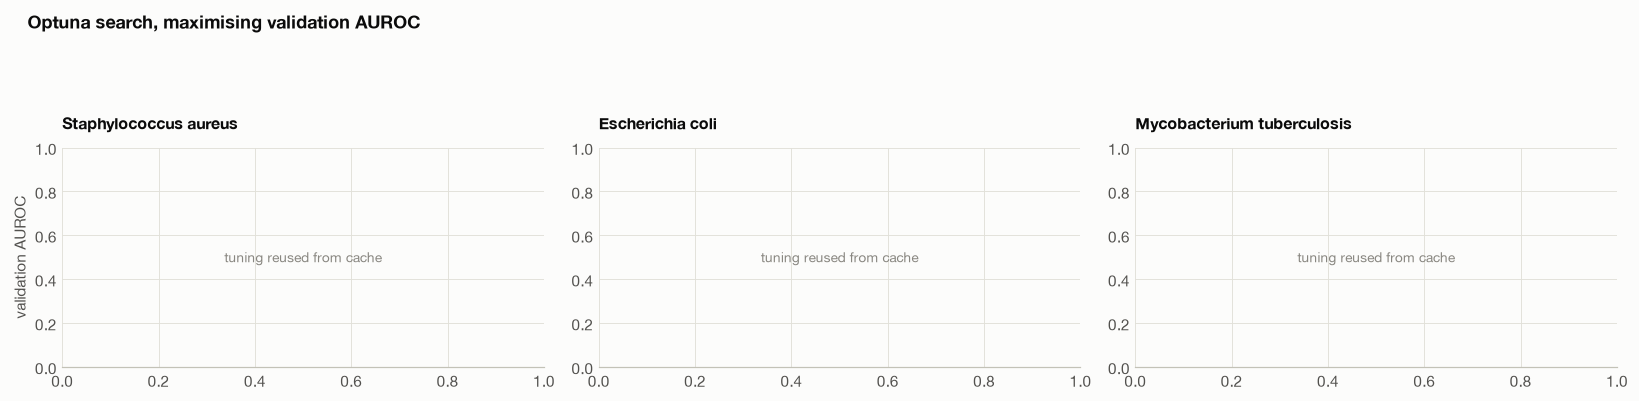

,feature set,model,untuned,tuned,gain
pathogen,,,,,
Staphylococcus aureus,hybrid,random_forest,0.870,0.880,0.010
Escherichia coli,hybrid,random_forest,0.882,0.888,0.006
Mycobacterium tuberculosis,morgan,random_forest,0.838,0.841,0.003


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    study = studies[organism]
    if study is None:
        ax.text(0.5, 0.5, "tuning reused from cache", ha="center", va="center",
                transform=ax.transAxes, fontsize=9, color=viz.MUTED)
        ax.set_title(organism, fontsize=10.5)
        continue
    values = [t.value for t in study.trials if t.value is not None]
    running = np.maximum.accumulate(values)
    ax.plot(range(1, len(values) + 1), values, marker="o", markersize=3.5, linewidth=0,
            color=viz.MUTED, label="trial")
    ax.plot(range(1, len(running) + 1), running, color=viz.SERIES[0], linewidth=2,
            label="best so far")
    baseline = summary.loc[(organism, *winners[organism]), "mean"]
    ax.axhline(baseline, color=viz.SERIES[1], linewidth=1.2, linestyle="--",
               label="untuned screen")
    ax.set_xlabel("trial")
    ax.set_title(organism, fontsize=10.5)
axes[0].set_ylabel("validation AUROC")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Optuna search, maximising validation AUROC", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_optuna")
plt.show()

def tuned_value(o):
    if studies[o] is not None:
        return studies[o].best_value
    return json.loads((data.PROCESSED / f"04_tuning_{curation.slug(o)}.json").read_text())["value"]


pd.DataFrame([
    {"pathogen": o, "feature set": winners[o][0], "model": winners[o][1],
     "untuned": summary.loc[(o, *winners[o]), "mean"], "tuned": tuned_value(o),
     "gain": tuned_value(o) - summary.loc[(o, *winners[o]), "mean"]}
    for o in CONFIG["pathogens"]
]).set_index("pathogen").style.format("{:.3f}", subset=["untuned", "tuned", "gain"])

## 4. Calibration

A tuned model ranks well and still reports probabilities that mean nothing in absolute terms.
Isotonic regression is fitted on the validation partition with the model frozen, so the fit never
touches either held-out set.

**What this can and cannot fix, measured rather than predicted.** Isotonic learns the mapping from
score to probability *at the validation base rate*, 39% to 59% active here. The plant holdout is
16% to 33% active, and a mapping fitted at one prevalence does not transport to another. The table
below shows what that costs, and it differs by pathogen rather than going one way: for *E. coli*
the raw model genuinely over-predicted on plants and calibration fixed it, while for *S. aureus*
the raw scores were already close to the observed rate and for *M. tuberculosis* calibration barely
moved them. On two of the three, the plant Brier score gets slightly **worse** after calibration.

That is the prevalence shift showing through, not a failed fit, and it is a limitation to report
rather than tune away. It is also the first of two reasons this notebook leads with ranking metrics
rather than absolute probabilities.

**One more caveat on the calibrator.** The validation partition now does three jobs: choosing the
feature set and model, serving as the Optuna objective, and fitting the calibrator. None of that
touches a test set, so it is not leakage, but the calibrator is being fitted on scores the
hyperparameters were tuned to maximise. Calibration will therefore transfer slightly worse than
the validation Brier suggests, which the raw and calibrated Brier columns below will show.

**And the second reason to keep the raw score.** Isotonic regression is a step function: it maps
thousands of distinct model scores onto a few dozen output levels. On the scaffold test set that
collapses 8,567 compounds to under eighty distinct values, so a top-5% cut would be decided by
hundreds of exact ties broken by row order rather than by the model. AUROC is unaffected, because
it averages over ties correctly, but precision at the head of a ranking is not. So from here on,
**ranking uses the raw model score and the calibrated probability is what gets displayed**.
Isotonic is monotone, so wherever the raw scores differ the two agree on order; raw simply keeps
the resolution that calibration discards.

In [7]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss

fitted, calibrated, calibration_rows = {}, {}, []
for organism in CONFIG["pathogens"]:
    feature_name, model_name = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    y = bundle["label"]
    X = featureset.matrices(bundle)[feature_name]
    weight = models.positive_weight(y[part["train"]])

    builder = models.gradient_boosting if model_name == "gradient_boosting" else models.random_forest
    extra = {"scale_pos_weight": weight} if model_name == "gradient_boosting" else {}
    model = builder(seed=CONFIG["seed"], **extra, **tuned[organism])
    model.fit(X[part["train"]], y[part["train"]])
    fitted[organism] = model

    wrapper = CalibratedClassifierCV(FrozenEstimator(model), method="isotonic")
    wrapper.fit(X[part["validation"]], y[part["validation"]])
    calibrated[organism] = wrapper

    for name in ("test", "plant"):
        raw = model.predict_proba(X[part[name]])[:, 1]
        cal = wrapper.predict_proba(X[part[name]])[:, 1]
        calibration_rows.append({
            "pathogen": organism,
            "set": name,
            "observed active rate": float(np.mean(y[part[name]])),
            "mean predicted, raw": float(np.mean(raw)),
            "mean predicted, calibrated": float(np.mean(cal)),
            "Brier raw": brier_score_loss(y[part[name]], raw),
            "Brier calibrated": brier_score_loss(y[part[name]], cal),
        })
calibration_table = pd.DataFrame(calibration_rows).set_index(["pathogen", "set"])
calibration_table.style.format("{:.3f}")

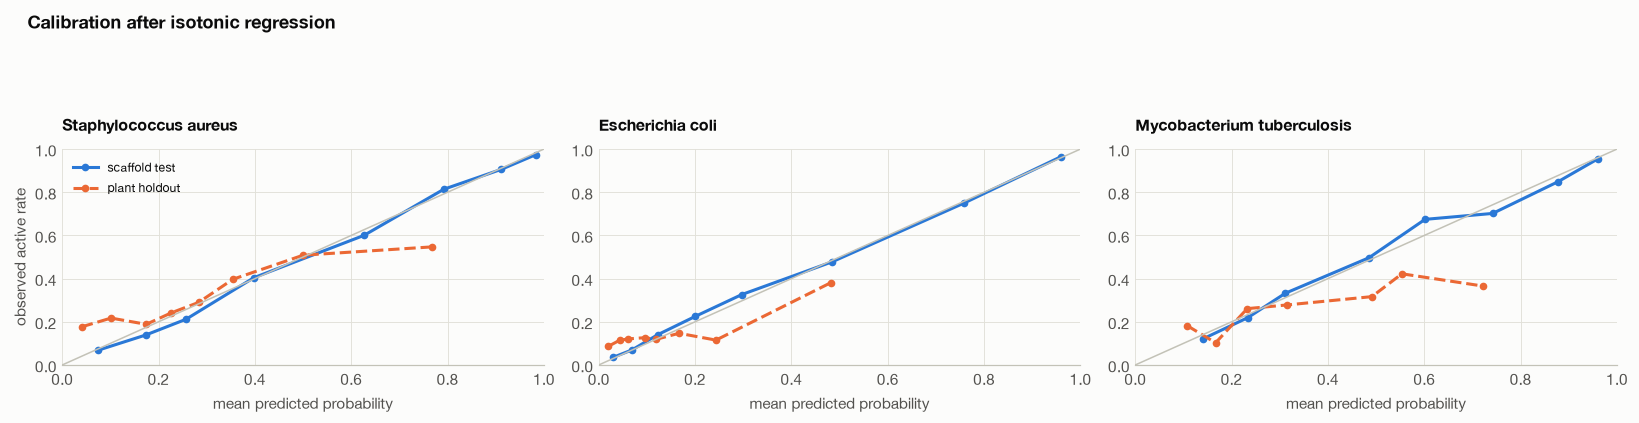

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, organism in zip(axes, CONFIG["pathogens"]):
    feature_name, _ = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    X = featureset.matrices(bundle)[feature_name]
    y = bundle["label"]
    for i, (name, style) in enumerate([("test", "-"), ("plant", "--")]):
        scores = calibrated[organism].predict_proba(X[part[name]])[:, 1]
        truth = y[part[name]]
        bins = np.quantile(scores, np.linspace(0, 1, 9))
        bins = np.unique(bins)
        which = np.clip(np.digitize(scores, bins[1:-1]), 0, len(bins) - 2)
        xs, ys = [], []
        for b in range(len(bins) - 1):
            mask = which == b
            if mask.sum() >= 20:
                xs.append(scores[mask].mean())
                ys.append(truth[mask].mean())
        ax.plot(xs, ys, style, marker="o", markersize=4, color=viz.SERIES[i],
                label="scaffold test" if name == "test" else "plant holdout")
    ax.plot([0, 1], [0, 1], color=viz.AXIS, linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("mean predicted probability")
    ax.set_title(organism, fontsize=10.5)
axes[0].set_ylabel("observed active rate")
axes[0].legend(fontsize=8)
fig.suptitle("Calibration after isotonic regression", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_calibration")
plt.show()

## 5. Scoring, once, on both held-out sets

Read-once evaluation. Precision and enrichment at the head of the ranking lead, because that is
what a synthesis budget buys; AUROC is reported beside them for comparability with the literature.
Ranking is on the raw model score for the reason just given, and `distinct_raw_scores` against
`distinct_calibrated_scores` shows how much resolution that preserves.

**Read the scaffold-test precision against its ceiling.** With a base rate of 54% there is no room
for a top-5% precision much above 1.0, so the maximum possible enrichment is only 1.86x and a
figure near it says almost nothing about the model. The `share_of_ceiling` column makes that
explicit: on the scaffold test set the metric is saturated, and on the plant holdout, where the
base rate is far lower, it still has headroom to measure something.

In [9]:
results, predictions = [], {}
for organism in CONFIG["pathogens"]:
    feature_name, model_name = winners[organism]
    bundle, part = bundles[organism], parts[organism]
    X = featureset.matrices(bundle)[feature_name]
    y = bundle["label"]
    for name in ("test", "plant"):
        raw_scores = fitted[organism].predict_proba(X[part[name]])[:, 1]
        cal_scores = calibrated[organism].predict_proba(X[part[name]])[:, 1]
        scores = raw_scores
        metrics = models.evaluate(y[part[name]], scores)
        metrics["distinct_raw_scores"] = int(len(np.unique(raw_scores)))
        metrics["distinct_calibrated_scores"] = int(len(np.unique(cal_scores)))
        truth = y[part[name]]
        low, high = models.bootstrap_metric(
            truth, scores, models.roc_auc_score, seed=CONFIG["seed"]
        )
        metrics.update({"pathogen": organism, "set": name,
                        "auroc_lo": low, "auroc_hi": high})
        for fraction in models.TOP_FRACTIONS:
            tag = f"{int(fraction * 100)}pct"
            plo, phi = models.bootstrap_metric(
                truth, scores,
                lambda a, b, f=fraction: models.precision_at(a, b, f),
                seed=CONFIG["seed"],
            )
            metrics[f"precision_top_{tag}_lo"] = plo
            metrics[f"precision_top_{tag}_hi"] = phi
            metrics[f"n_top_{tag}"] = max(1, int(round(fraction * len(truth))))
        results.append(metrics)
        predictions[(organism, name)] = pd.DataFrame({
            "skeleton": bundle["skeleton"][part[name]],
            "label": y[part[name]],
            "score": raw_scores,
            "score_calibrated": cal_scores,
        })
results = pd.DataFrame(results).set_index(["pathogen", "set"])
results["enrichment_ceiling_top_5pct"] = np.minimum(1.0 / results.base_rate, 20.0)
results["share_of_ceiling"] = results.enrichment_top_5pct / results.enrichment_ceiling_top_5pct
show = ["n", "base_rate", "auroc", "auroc_lo", "auroc_hi",
        "n_top_1pct", "precision_top_1pct", "precision_top_1pct_lo", "precision_top_1pct_hi",
        "n_top_5pct", "precision_top_5pct", "precision_top_5pct_lo", "precision_top_5pct_hi",
        "enrichment_top_5pct", "enrichment_ceiling_top_5pct", "share_of_ceiling",
        "distinct_raw_scores", "distinct_calibrated_scores"]
display(results[show].style.format(
    "{:.3f}", subset=[c for c in show if not c.startswith("n")]
))

print("Compounds behind each top-k precision, which is how far they can be read:")
print(results[["n", "n_top_1pct", "n_top_5pct", "n_top_10pct"]].to_string())

Compounds behind each top-k precision, which is how far they can be read:
                                     n  n_top_1pct  n_top_5pct  n_top_10pct
pathogen                   set                                             
Staphylococcus aureus      test   8567          86         428          857
                           plant  1432          14          72          143
Escherichia coli           test   6404          64         320          640
                           plant   867           9          43           87
Mycobacterium tuberculosis test   3371          34         169          337
                           plant   688           7          34           69


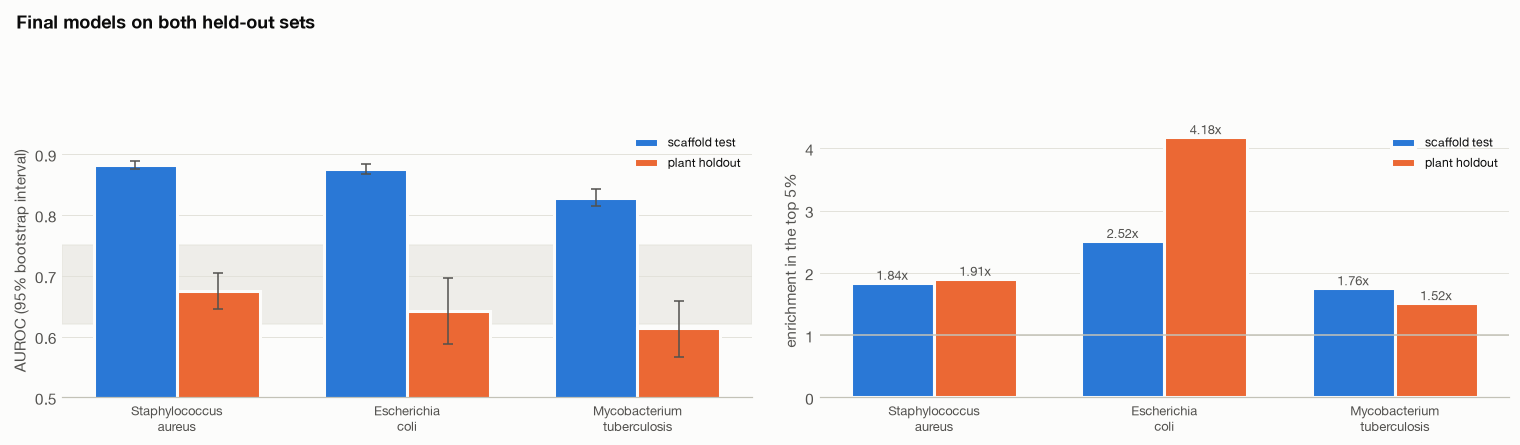

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = np.arange(len(CONFIG["pathogens"]))
width = 0.36
for i, name in enumerate(("test", "plant")):
    tag = "scaffold test" if name == "test" else "plant holdout"
    aurocs = [results.loc[(o, name), "auroc"] for o in CONFIG["pathogens"]]
    lo = [results.loc[(o, name), "auroc"] - results.loc[(o, name), "auroc_lo"]
          for o in CONFIG["pathogens"]]
    hi = [results.loc[(o, name), "auroc_hi"] - results.loc[(o, name), "auroc"]
          for o in CONFIG["pathogens"]]
    axes[0].bar(x + (i - 0.5) * width, aurocs, width=width, yerr=[lo, hi], capsize=3,
                color=viz.SERIES[i], edgecolor=viz.SURFACE, linewidth=2,
                error_kw=dict(ecolor=viz.INK_SECONDARY, lw=1), label=tag)
    enrich = [results.loc[(o, name), "enrichment_top_5pct"] for o in CONFIG["pathogens"]]
    axes[1].bar(x + (i - 0.5) * width, enrich, width=width, color=viz.SERIES[i],
                edgecolor=viz.SURFACE, linewidth=2, label=tag)
    for xi, v in zip(x + (i - 0.5) * width, enrich):
        axes[1].text(xi, v, f"{v:.2f}x", ha="center", va="bottom", fontsize=8.5,
                     color=viz.INK_SECONDARY)
axes[0].axhspan(0.62, 0.75, color=viz.GRID, alpha=0.5, zorder=0)
axes[0].set_ylim(0.5, 0.95)
axes[0].set_ylabel("AUROC (95% bootstrap interval)")
axes[1].axhline(1.0, color=viz.AXIS, linewidth=1)
axes[1].set_ylabel("enrichment in the top 5%")
for ax in axes:
    ax.set_xticks(x, [o.replace(" ", "\n") for o in CONFIG["pathogens"]], fontsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8)
fig.suptitle("Final models on both held-out sets", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "04_held_out")
plt.show()

## 6. Save, and record the runs

In [11]:
written = []
for organism in CONFIG["pathogens"]:
    slug = curation.slug(organism)
    feature_name, model_name = winners[organism]
    payload = {
        "organism": organism,
        "feature_set": feature_name,
        "model": model_name,
        "params": tuned[organism],
        "model_object": fitted[organism],
        "calibrator": calibrated[organism],
    }
    path = data.PROCESSED / f"04_models_{slug}.pkl"
    path.write_bytes(pickle.dumps(payload))
    for name in ("test", "plant"):
        data.save_processed(predictions[(organism, name)], f"04_scores_{slug}_{name}")
    written.append({"pathogen": organism, "path": str(path.relative_to(ROOT)),
                    "MB": round(path.stat().st_size / 1e6, 1)})

    entry = ledger.record(
        f"model_{slug}",
        {
            "task": f"{organism} MIC, whole organism",
            "threshold_um": curation.PRIMARY_THRESHOLD_UM,
            "feature_set": feature_name,
            "model": model_name,
            "tuning": f"optuna TPE, {CONFIG['optuna_trials']} trials, validation AUROC",
            "tuning_source": tuning_source[organism],
            "data_fingerprint": data_fingerprint(organism),
            "threshold_um": curation.PRIMARY_THRESHOLD_UM,
            "params": tuned[organism],
            "calibration": CONFIG["calibration"],
            "split": "scaffold group split, plant-derived compounds held out of training",
        },
        {
            "validation_auroc": tuned_value(organism),
            "test_auroc": results.loc[(organism, "test"), "auroc"],
            "plant_auroc": results.loc[(organism, "plant"), "auroc"],
            "plant_precision_top_5pct": results.loc[(organism, "plant"), "precision_top_5pct"],
            "plant_enrichment_top_5pct": results.loc[(organism, "plant"), "enrichment_top_5pct"],
            "plant_base_rate": results.loc[(organism, "plant"), "base_rate"],
        },
        note="tuned model, scored on the scaffold test set and the plant holdout",
    )
    print(f"{organism}: ledger {entry['id']}")
pd.DataFrame(written).set_index("pathogen")

Staphylococcus aureus: ledger 2026-11-04T04:15:42_model_staphylococcus_aureus


Escherichia coli: ledger 2026-11-04T04:15:42_model_escherichia_coli
Mycobacterium tuberculosis: ledger 2026-11-04T04:15:43_model_mycobacterium_tuberculosis


,path,MB
pathogen,,
Staphylococcus aureus,data/processed/04_models_staphylococcus_aureus...,633.1
Escherichia coli,data/processed/04_models_escherichia_coli.pkl,289.6
Mycobacterium tuberculosis,data/processed/04_models_mycobacterium_tubercu...,87.4


## 7. What 05 is getting

Filled in from the numbers above after the run.